# Notebook 03: Model Architecture (ResNet + U-Net Decoder)

In this notebook, we build our deep neural network for **Image Colorization**!

### Why U-Net with Skip Connections?
- **Encoder:** Compresses the image down into abstract semantic understanding (*"What is in this image? Is it sky, tree leaves, skin, water, or sand?"*).
- **Skip Connections:** Directly pass high-resolution edge details from the encoder to the decoder so colors **don't bleed** across object boundaries.
- **Decoder:** Upsamples back from $8\times8$ to $256\times256$, predicting the 2 color channels ($a$ and $b$).
- **`Tanh` Output:** Restricts color predictions strictly between $[-1, 1]$, perfectly matching our normalized color targets.

### 1. Import Libraries & Set Up Python Path

In [18]:
import os
import sys
# Add project root to sys.path so we can import from src
sys.path.append(os.path.abspath(".."))

import torch
import torch.nn as nn
import torchvision.models as models
import matplotlib.pyplot as plt
from PIL import Image
from skimage import color
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


### 2. Building Blocks: `ConvBlock` and `UnetUpBlock`

- **`ConvBlock`**: Two consecutive $3\times3$ convolutions with Batch Normalization and ReLU activations.
- **`UnetUpBlock`**: Upsamples feature maps by $2\times$, concatenates the matching skip connection from the encoder, and processes with a `ConvBlock`.

In [19]:
class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class UnetUpBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True)
        self.conv = ConvBlock(in_c, out_c)
        
    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)

### 3. The Full `ResNetColorizationNet`

- **Input:** `L` channel (1, 256, 256)
- **Encoder:** Pretrained ResNet-18 (we adapt `conv1` from 3 channels to 1 channel)
- **Decoder:** 4 U-Net upsampling stages with skip connections
- **Output:** `ab` channels (2, 256, 256) through `Tanh`

In [20]:
class ResNetColorizationNet(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        resnet = models.resnet18(weights=weights)

        # Adapt first conv layer: in_channels=1 (Grayscale L) instead of 3 (RGB)
        w = resnet.conv1.weight.data
        resnet.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        resnet.conv1.weight.data = w.sum(dim=1, keepdim=True)  # Sum RGB weights for L

        # Encoder (ResNet stages)
        self.init_conv = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)  # 64,  128x128
        self.maxpool = resnet.maxpool                                          # 64,  64x64
        self.layer1 = resnet.layer1                                            # 64,  64x64
        self.layer2 = resnet.layer2                                            # 128, 32x32
        self.layer3 = resnet.layer3                                            # 256, 16x16
        self.layer4 = resnet.layer4                                            # 512, 8x8

        # Decoder with skip connections
        self.up4 = UnetUpBlock(512 + 256, 256)  # 8x8   -> 16x16
        self.up3 = UnetUpBlock(256 + 128, 128)  # 16x16 -> 32x32
        self.up2 = UnetUpBlock(128 + 64, 64)    # 32x32 -> 64x64
        self.up1 = UnetUpBlock(64 + 64, 32)     # 64x64 -> 128x128

        # Final upsampling: 128x128 -> 256x256
        self.final_up = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True),
            nn.Conv2d(32, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 2, kernel_size=1),  # 2 channels: 'a' and 'b'
            nn.Tanh()                         # Output range [-1, 1]
        )

    def forward(self, L):
        # Encoder
        x0 = self.init_conv(L)             # (B, 64,  128, 128)
        x1 = self.layer1(self.maxpool(x0)) # (B, 64,  64,  64)
        x2 = self.layer2(x1)               # (B, 128, 32,  32)
        x3 = self.layer3(x2)               # (B, 256, 16,  16)
        x4 = self.layer4(x3)               # (B, 512, 8,   8)

        # Decoder with skip connections
        d4 = self.up4(x4, x3)              # (B, 256, 16,  16)
        d3 = self.up3(d4, x2)              # (B, 128, 32,  32)
        d2 = self.up2(d3, x1)              # (B, 64,  64,  64)
        d1 = self.up1(d2, x0)              # (B, 32,  128, 128)
        out_ab = self.final_up(d1)         # (B, 2,   256, 256)

        return out_ab

### 4. Instantiate Model & Verify Tensor Shapes

In [21]:
model = ResNetColorizationNet(pretrained=True).to(device)

# Create a dummy input tensor: 4 grayscale images of size 256x256
dummy_input = torch.randn(4, 1, 256, 256).to(device)
dummy_output = model(dummy_input)

print("Dummy Input shape :", dummy_input.shape, " -> [Batch, 1 Channel (L), Height, Width]")
print("Dummy Output shape:", dummy_output.shape, "-> [Batch, 2 Channels (ab), Height, Width]")
print("Output range      :", round(float(dummy_output.min()), 2), "to", round(float(dummy_output.max()), 2))

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params / 1e6:.2f} Million")

Dummy Input shape : torch.Size([4, 1, 256, 256])  -> [Batch, 1 Channel (L), Height, Width]
Dummy Output shape: torch.Size([4, 2, 256, 256]) -> [Batch, 2 Channels (ab), Height, Width]
Output range      : -0.95 to 0.22
Total trainable parameters: 14.32 Million


### 5. Untrained Model Sanity Check
Let's pass a real image through the untrained network to observe its baseline before learning:

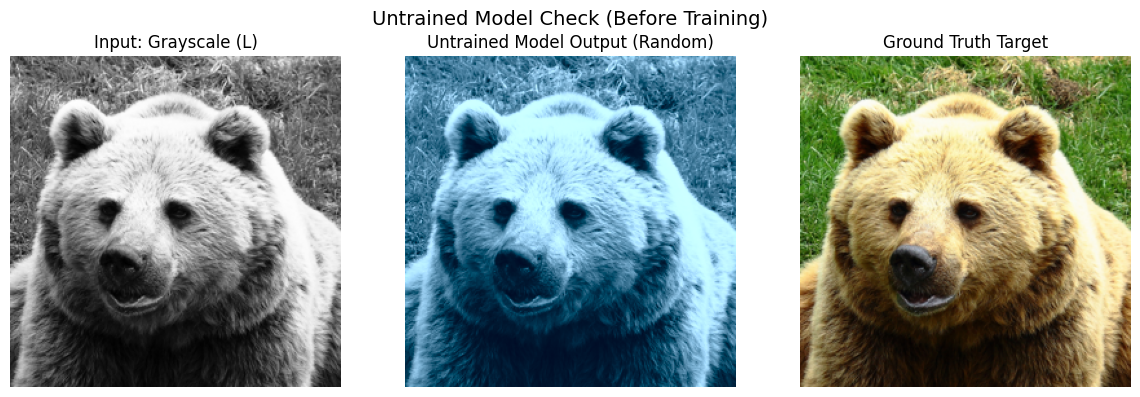

In [22]:
def lab_to_rgb(L_tensor, ab_tensor):
    """Converts normalized L (1, H, W) and ab (2, H, W) back to RGB [0, 1]."""
    L_np = L_tensor.squeeze().detach().cpu().numpy()
    ab_np = ab_tensor.detach().cpu().numpy().transpose(1, 2, 0)
    L_denorm = (L_np + 1.0) * 50.0
    ab_denorm = ab_np * 128.0
    H, W = L_np.shape
    lab = np.zeros((H, W, 3), dtype=np.float64)
    lab[:, :, 0] = L_denorm
    lab[:, :, 1:] = ab_denorm
    rgb = color.lab2rgb(lab)
    return np.clip(rgb, 0.0, 1.0)

# Load a sample image
train_dir = os.path.join("..", "data", "raw", "train")
sample_file = os.path.join(train_dir, os.listdir(train_dir)[0])

img_pil = Image.open(sample_file).convert("RGB").resize((256, 256))
img_np = np.array(img_pil)
img_lab = color.rgb2lab(img_np).astype(np.float32)

L = (img_lab[:, :, 0] / 50.0) - 1.0
L_tensor = torch.from_numpy(L).unsqueeze(0).unsqueeze(0).to(device)  # (1, 1, 256, 256)

# Inference with untrained model
model.eval()
with torch.no_grad():
    predicted_ab = model(L_tensor).squeeze(0)  # (2, 256, 256)

untrained_rgb = lab_to_rgb(L_tensor.squeeze(0), predicted_ab)

# Display Before vs After Training Preview
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img_pil.convert("L"), cmap="gray")
axes[0].set_title("Input: Grayscale (L)")
axes[0].axis("off")

axes[1].imshow(untrained_rgb)
axes[1].set_title("Untrained Model Output (Random)")
axes[1].axis("off")

axes[2].imshow(img_pil)
axes[2].set_title("Ground Truth Target")
axes[2].axis("off")

plt.suptitle("Untrained Model Check (Before Training)", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

### Summary & Next Step

- We built our **`ResNetColorizationNet`** (14.3 Million parameters).
- It accepts `(B, 1, 256, 256)` and outputs `(B, 2, 256, 256)` bounded to $[-1, 1]$.
- It uses pretrained ResNet-18 feature extraction so it converges in **under 15–20 minutes** on your RTX 4050 GPU.

👉 **Next Notebook:** `04_training.ipynb` where we train the network, track losses, and watch it learn to colorize epoch by epoch!